In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully")

Libraries loaded successfully


Load data

In [2]:
PROCESSED_PATH = "../data/processed/"

customers = pd.read_csv(
    f"{PROCESSED_PATH}customers_clean.csv"
)

orders = pd.read_csv(
    f"{PROCESSED_PATH}orders_analytics.csv"
)

print("Customers:", customers.shape)
print("Orders:", orders.shape)

Customers: (99441, 5)
Orders: (99441, 22)


Convert order date

In [3]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print(
    orders["order_purchase_timestamp"].min(),
    "to",
    orders["order_purchase_timestamp"].max()
)

2016-09-04 21:15:19 to 2018-10-17 17:30:18


Keep delivered orders

In [4]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Delivered orders:", len(delivered_orders))

Delivered orders: 96478


Create customer-level data
(We need customer_unique_id, not just customer_id, because one real customer can potentially have multiple customer records.)

In [5]:
customer_orders = delivered_orders.merge(
    customers[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

print(customer_orders.shape)

(96478, 23)


Set analysis date

For RFM:

Recency = how recently the customer purchased
Frequency = how many orders they made
Monetary = how much they spent

In [6]:
analysis_date = (
    customer_orders["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

print("Analysis date:", analysis_date)

Analysis date: 2018-08-30 15:00:37


Calculate RFM

In [7]:
rfm = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        Recency=(
            "order_purchase_timestamp",
            lambda x: (
                analysis_date - x.max()
            ).days
        ),
        Frequency=(
            "order_id",
            "nunique"
        ),
        Monetary=(
            "total_order_value",
            "sum"
        )
    )
    .reset_index()
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19
2,0000f46a3911fa3c0805444483337064,537,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89


Inspect RFM

In [8]:
rfm.describe()

,Recency,Frequency,Monetary
count,93358.000000,93358.000000,93358.000000
mean,237.941773,1.033420,165.168210
std,152.591453,0.209097,226.292101
min,1.000000,1.000000,9.590000
25%,114.000000,1.000000,63.010000
50%,219.000000,1.000000,107.780000
75%,346.000000,1.000000,182.510000
max,714.000000,15.000000,13664.080000


Create RFM scores

In [9]:
rfm["R_score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1],
    duplicates="drop"
)

rfm["F_score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop"
)

Convert scores to integers

In [10]:
rfm["R_score"] = rfm["R_score"].astype(int)
rfm["F_score"] = rfm["F_score"].astype(int)
rfm["M_score"] = rfm["M_score"].astype(int)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,4,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,4,1,1,411
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4,214


Create customer segments

In [11]:
def segment_customer(row):

    r = row["R_score"]
    f = row["F_score"]
    m = row["M_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 3:
        return "Loyal Customers"

    elif r >= 4 and f <= 2:
        return "New Customers"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Lost Customers"

    else:
        return "Potential Loyalists"


rfm["Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,4,414,New Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,4,1,1,411,New Customers
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,112,Lost Customers
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,211,Lost Customers
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4,214,Lost Customers


Segment distribution

In [12]:
segment_counts = (
    rfm["Segment"]
    .value_counts()
)

print(segment_counts)

Segment
Loyal Customers        27288
At Risk                22230
Lost Customers         14986
New Customers          14984
Potential Loyalists     7373
Champions               6497
Name: count, dtype: int64


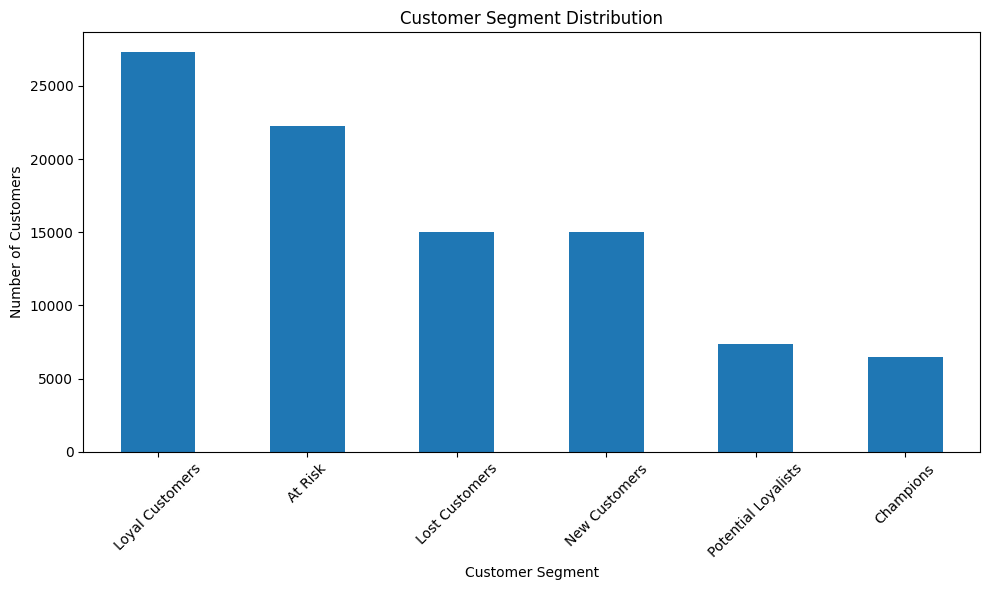

In [13]:
plt.figure(figsize=(10, 6))

segment_counts.plot(kind="bar")

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Segment revenue

In [14]:
segment_revenue = (
    rfm
    .groupby("Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

print(segment_revenue)

Segment
At Risk                3711040.44
Loyal Customers        3656307.20
New Customers          2448694.43
Lost Customers         2441759.58
Champions              2027030.50
Potential Loyalists    1134941.60
Name: Monetary, dtype: float64


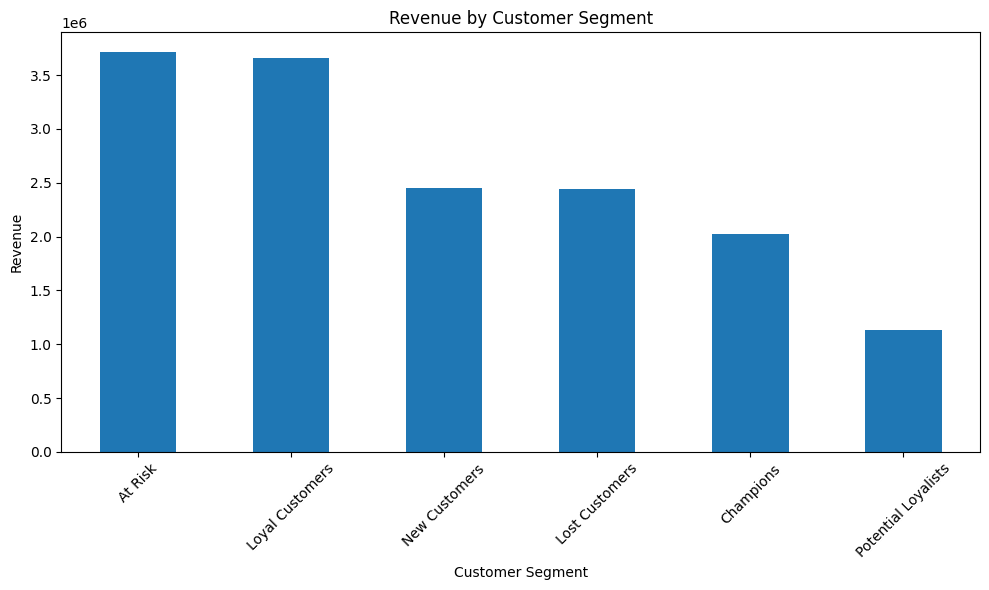

In [15]:
plt.figure(figsize=(10, 6))

segment_revenue.plot(kind="bar")

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [16]:
rfm.to_csv(
    f"{PROCESSED_PATH}customer_rfm_advanced.csv",
    index=False
)

print("RFM analysis saved successfully")

RFM analysis saved successfully


                 Olist
                   ↓
              SQL Analytics
                   ↓
                  EDA
                   ↓
              RFM Analysis
                   ↓
          Customer Segmentation
                   ↓
        ┌──────────┴──────────┐
        ↓                     ↓
   ML Analytics         AI Recommendation
                              Agent
                              